# Tree-Based Methods

We import some of our usual libraries at this top
level.

In [1]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import sklearn.model_selection as skm
from ISLP import load_data, confusion_table
from ISLP.models import ModelSpec as MS


We also  collect the new imports
needed for this lab.

In [2]:
from sklearn.tree import (DecisionTreeClassifier as DTC,
                          DecisionTreeRegressor as DTR,
                          plot_tree,
                          export_text)
from sklearn.metrics import (accuracy_score,
                             log_loss)
from sklearn.ensemble import \
     (RandomForestRegressor as RF,
      GradientBoostingRegressor as GBR)
from ISLP.bart import BART


## Fitting Classification Trees

We first use classification trees to analyze the  `Carseats`  data set.
In these data, `Sales` is a continuous variable, and so we begin
by recoding it as a binary variable. We use the `where()` 
function to create a variable, called `High`, which takes on a
value of `Yes` if the `Sales` variable exceeds 8, and takes
on a value of `No` otherwise.

In [3]:
Carseats = load_data('Carseats')
High = np.where(Carseats.Sales > 8,
                "Yes",
                "No")


We now use `DecisionTreeClassifier()`  to fit a classification tree in
order to predict `High` using all variables but `Sales`.
To do so, we must form a model matrix as we did when fitting regression
models.  

In [4]:
model = MS(Carseats.columns.drop('Sales'), intercept=False)
D = model.fit_transform(Carseats)
feature_names = list(D.columns)
X = np.asarray(D)
print(D)


     CompPrice  Income  Advertising  Population  Price  ShelveLoc[Good]  \
0        138.0    73.0         11.0       276.0  120.0              0.0   
1        111.0    48.0         16.0       260.0   83.0              1.0   
2        113.0    35.0         10.0       269.0   80.0              0.0   
3        117.0   100.0          4.0       466.0   97.0              0.0   
4        141.0    64.0          3.0       340.0  128.0              0.0   
..         ...     ...          ...         ...    ...              ...   
395      138.0   108.0         17.0       203.0  128.0              1.0   
396      139.0    23.0          3.0        37.0  120.0              0.0   
397      162.0    26.0         12.0       368.0  159.0              0.0   
398      100.0    79.0          7.0       284.0   95.0              0.0   
399      134.0    37.0          0.0        27.0  120.0              1.0   

     ShelveLoc[Medium]   Age  Education  Urban[Yes]  US[Yes]  
0                  0.0  42.0       1

c:\Users\Vicente\Desktop\Lund - MSc Economics\ML - From a Regression perspective\ml-course\.venv\Lib\site-packages\sklearn\base.py:969: FutureWarning: ModelSpec will move to its own package in ISLP 0.7. `from ISLP.models import ModelSpec` (and the other tools of ISLP.models that build model matrices) will keep working, but other import paths, such as ISLP.models.model_spec, may not, and `intercept` will then default to False. To silence this warning: warnings.filterwarnings('ignore', message='ModelSpec will move').
  return self.fit(X, **fit_params).transform(X)


**Exercise 1**: Read the [ModelSpec documentation](https://islp.readthedocs.io/en/latest/models/spec.html) to understand the purpose of `ModelSpec` (`MS`) for building model matrices.

We have converted `D` from a data frame to an array `X`, which is needed in some of the analysis below. We also need the `feature_names` for annotating our plots later.

There are several options needed to specify the  classifier,
such as `max_depth` (how deep to grow the tree), `min_samples_split`
(minimum number of observations in a node to be eligible for splitting)
and `criterion` (whether to use Gini or cross-entropy as the split criterion).
We also set `random_state` for reproducibility; ties in the split criterion are broken at random.

In [5]:
clf = DTC(criterion='entropy',
          max_depth=3,
          random_state=0)        
clf.fit(X, High)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In our discussion of qualitative features in Section 3.3,
we noted that for a linear regression model such a feature could be
represented by including a matrix of dummy variables (one-hot-encoding) in the model
matrix, using the formula notation of `statsmodels`.
As mentioned in Section 8.1, there is a more
natural way to handle qualitative features when building a decision
tree, that does not require such dummy variables; each split amounts to partitioning the levels into two groups.
However, 
the `sklearn` implementation of decision trees does not take
advantage of this approach; instead it simply treats the one-hot-encoded levels as separate variables.

In [6]:
accuracy_score(High, clf.predict(X))


0.79

With only the default arguments, the training error rate is
21%.
For classification trees, we can
access the value of the deviance using `log_loss()`,
\begin{equation*}
\begin{split}
-2 \sum_m \sum_k n_{mk} \log \hat{p}_{mk},
\end{split}
\end{equation*}
where $n_{mk}$ is the number of observations in the $m$th terminal
node that belong to the $k$th class.

In [7]:
resid_dev = np.sum(log_loss(High, clf.predict_proba(X)))
resid_dev


np.float64(0.4710647062649358)

This is closely related to the *entropy*, defined in (8.7).
A small deviance indicates a
tree that provides a good fit to the (training) data.
 
One of the most attractive properties of trees is that they can
be graphically displayed. Here we use the `plot()`  function
to display the tree structure.

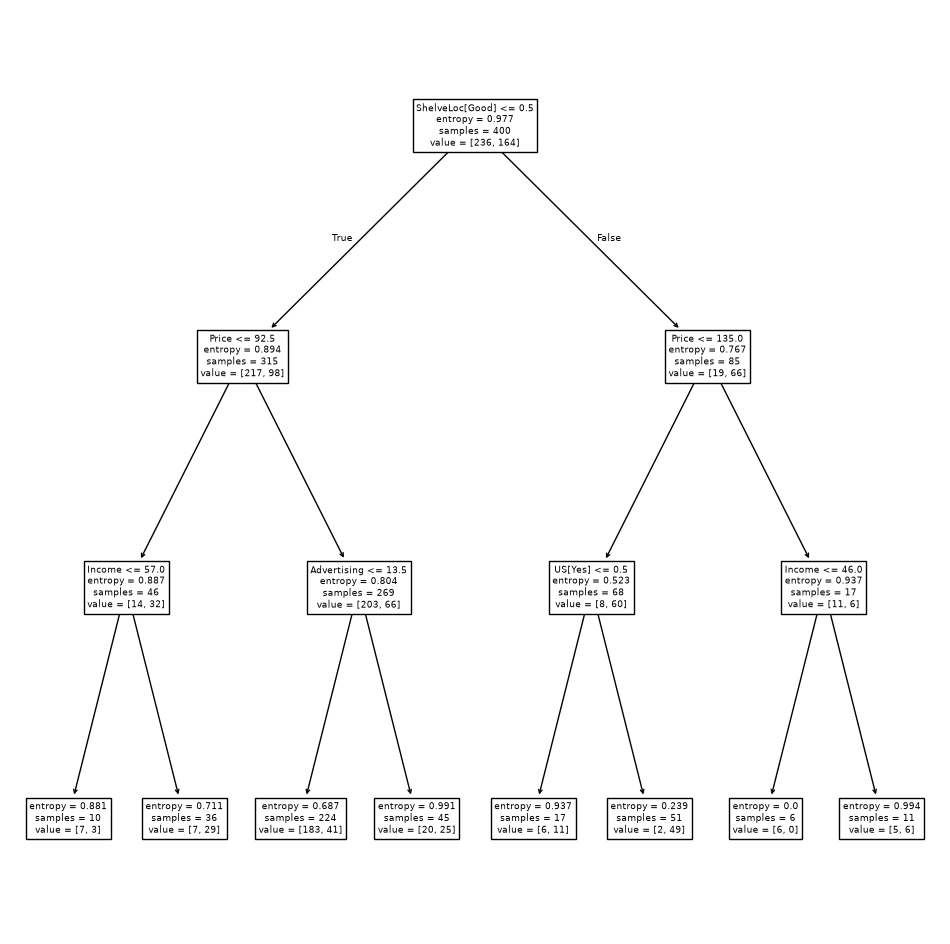

In [8]:
ax = subplots(figsize=(12,12))[1]
plot_tree(clf,
          feature_names=feature_names,
          ax=ax);


The most important indicator of `Sales` appears to be `ShelveLoc`.

We can see a text representation of the tree using
`export_text()`, which displays the split
criterion (e.g. `Price <= 92.5`) for each branch.
For leaf nodes it shows the overall prediction  
(`Yes` or `No`). 
 We can also see the number of observations in that
leaf that take on values of `Yes` and `No` by specifying  `show_weights=True`.

In [9]:
print(export_text(clf,
                  feature_names=feature_names,
                  show_weights=True))


|--- ShelveLoc[Good] <= 0.50
|   |--- Price <= 92.50
|   |   |--- Income <= 57.00
|   |   |   |--- weights: [7.00, 3.00] class: No
|   |   |--- Income >  57.00
|   |   |   |--- weights: [7.00, 29.00] class: Yes
|   |--- Price >  92.50
|   |   |--- Advertising <= 13.50
|   |   |   |--- weights: [183.00, 41.00] class: No
|   |   |--- Advertising >  13.50
|   |   |   |--- weights: [20.00, 25.00] class: Yes
|--- ShelveLoc[Good] >  0.50
|   |--- Price <= 135.00
|   |   |--- US[Yes] <= 0.50
|   |   |   |--- weights: [6.00, 11.00] class: Yes
|   |   |--- US[Yes] >  0.50
|   |   |   |--- weights: [2.00, 49.00] class: Yes
|   |--- Price >  135.00
|   |   |--- Income <= 46.00
|   |   |   |--- weights: [6.00, 0.00] class: No
|   |   |--- Income >  46.00
|   |   |   |--- weights: [5.00, 6.00] class: Yes



In order to properly evaluate the performance of a classification tree
on these data, we must estimate the test error rather than simply
computing the training error. We split the observations into a
training set and a test set, build the tree using the training set,
and evaluate its performance on the test data. This pattern is
similar to that in Chapter 6, with the linear models
replaced here by decision trees --- the code for validation
is almost identical. This approach leads to correct predictions
for 68.5% of the locations in the test data set.

In [10]:
validation = skm.ShuffleSplit(n_splits=1,
                              test_size=200,
                              random_state=0)
results = skm.cross_validate(clf,
                             D,
                             High,
                             cv=validation)
results['test_score']


array([0.685])

**Exercise 2**: Read the [ShuffleSplit documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.ShuffleSplit.html) to understand how `ShuffleSplit` creates randomized training and test sets.


Next, we consider whether pruning the tree might lead to improved
classification performance. We first split the data into a training and
test set. We will use cross-validation to prune the tree on the training
set, and then evaluate the performance of the pruned tree on the test
set.

In [11]:
(X_train,
 X_test,
 High_train,
 High_test) = skm.train_test_split(X,
                                   High,
                                   test_size=0.5,
                                   random_state=0)
                                   

We first refit the full tree on the training set; here we do not set a `max_depth` parameter, since we will learn that through cross-validation.


In [12]:
clf = DTC(criterion='entropy', random_state=0)
clf.fit(X_train, High_train)
accuracy_score(High_test, clf.predict(X_test))


0.735

Next we use the `cost_complexity_pruning_path()` method of
`clf` to extract cost-complexity values. 

In [13]:
ccp_path = clf.cost_complexity_pruning_path(X_train, High_train)
kfold = skm.KFold(10,
                  random_state=1,
                  shuffle=True)


**Exercise 3**: Read the [Cost-Complexity Pruning documentation](https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html) to understand how `sklearn` uses cost-complexity pruning (`ccp_alpha`) to simplify decision trees.

This yields a set of impurities and $\alpha$ values
from which we can extract an optimal one by cross-validation.

In [14]:
grid = skm.GridSearchCV(clf,
                        {'ccp_alpha': ccp_path.ccp_alphas},
                        refit=True,
                        cv=kfold,
                        scoring='accuracy')
grid.fit(X_train, High_train)
grid.best_score_

np.float64(0.685)

Let’s take a look at the pruned true.

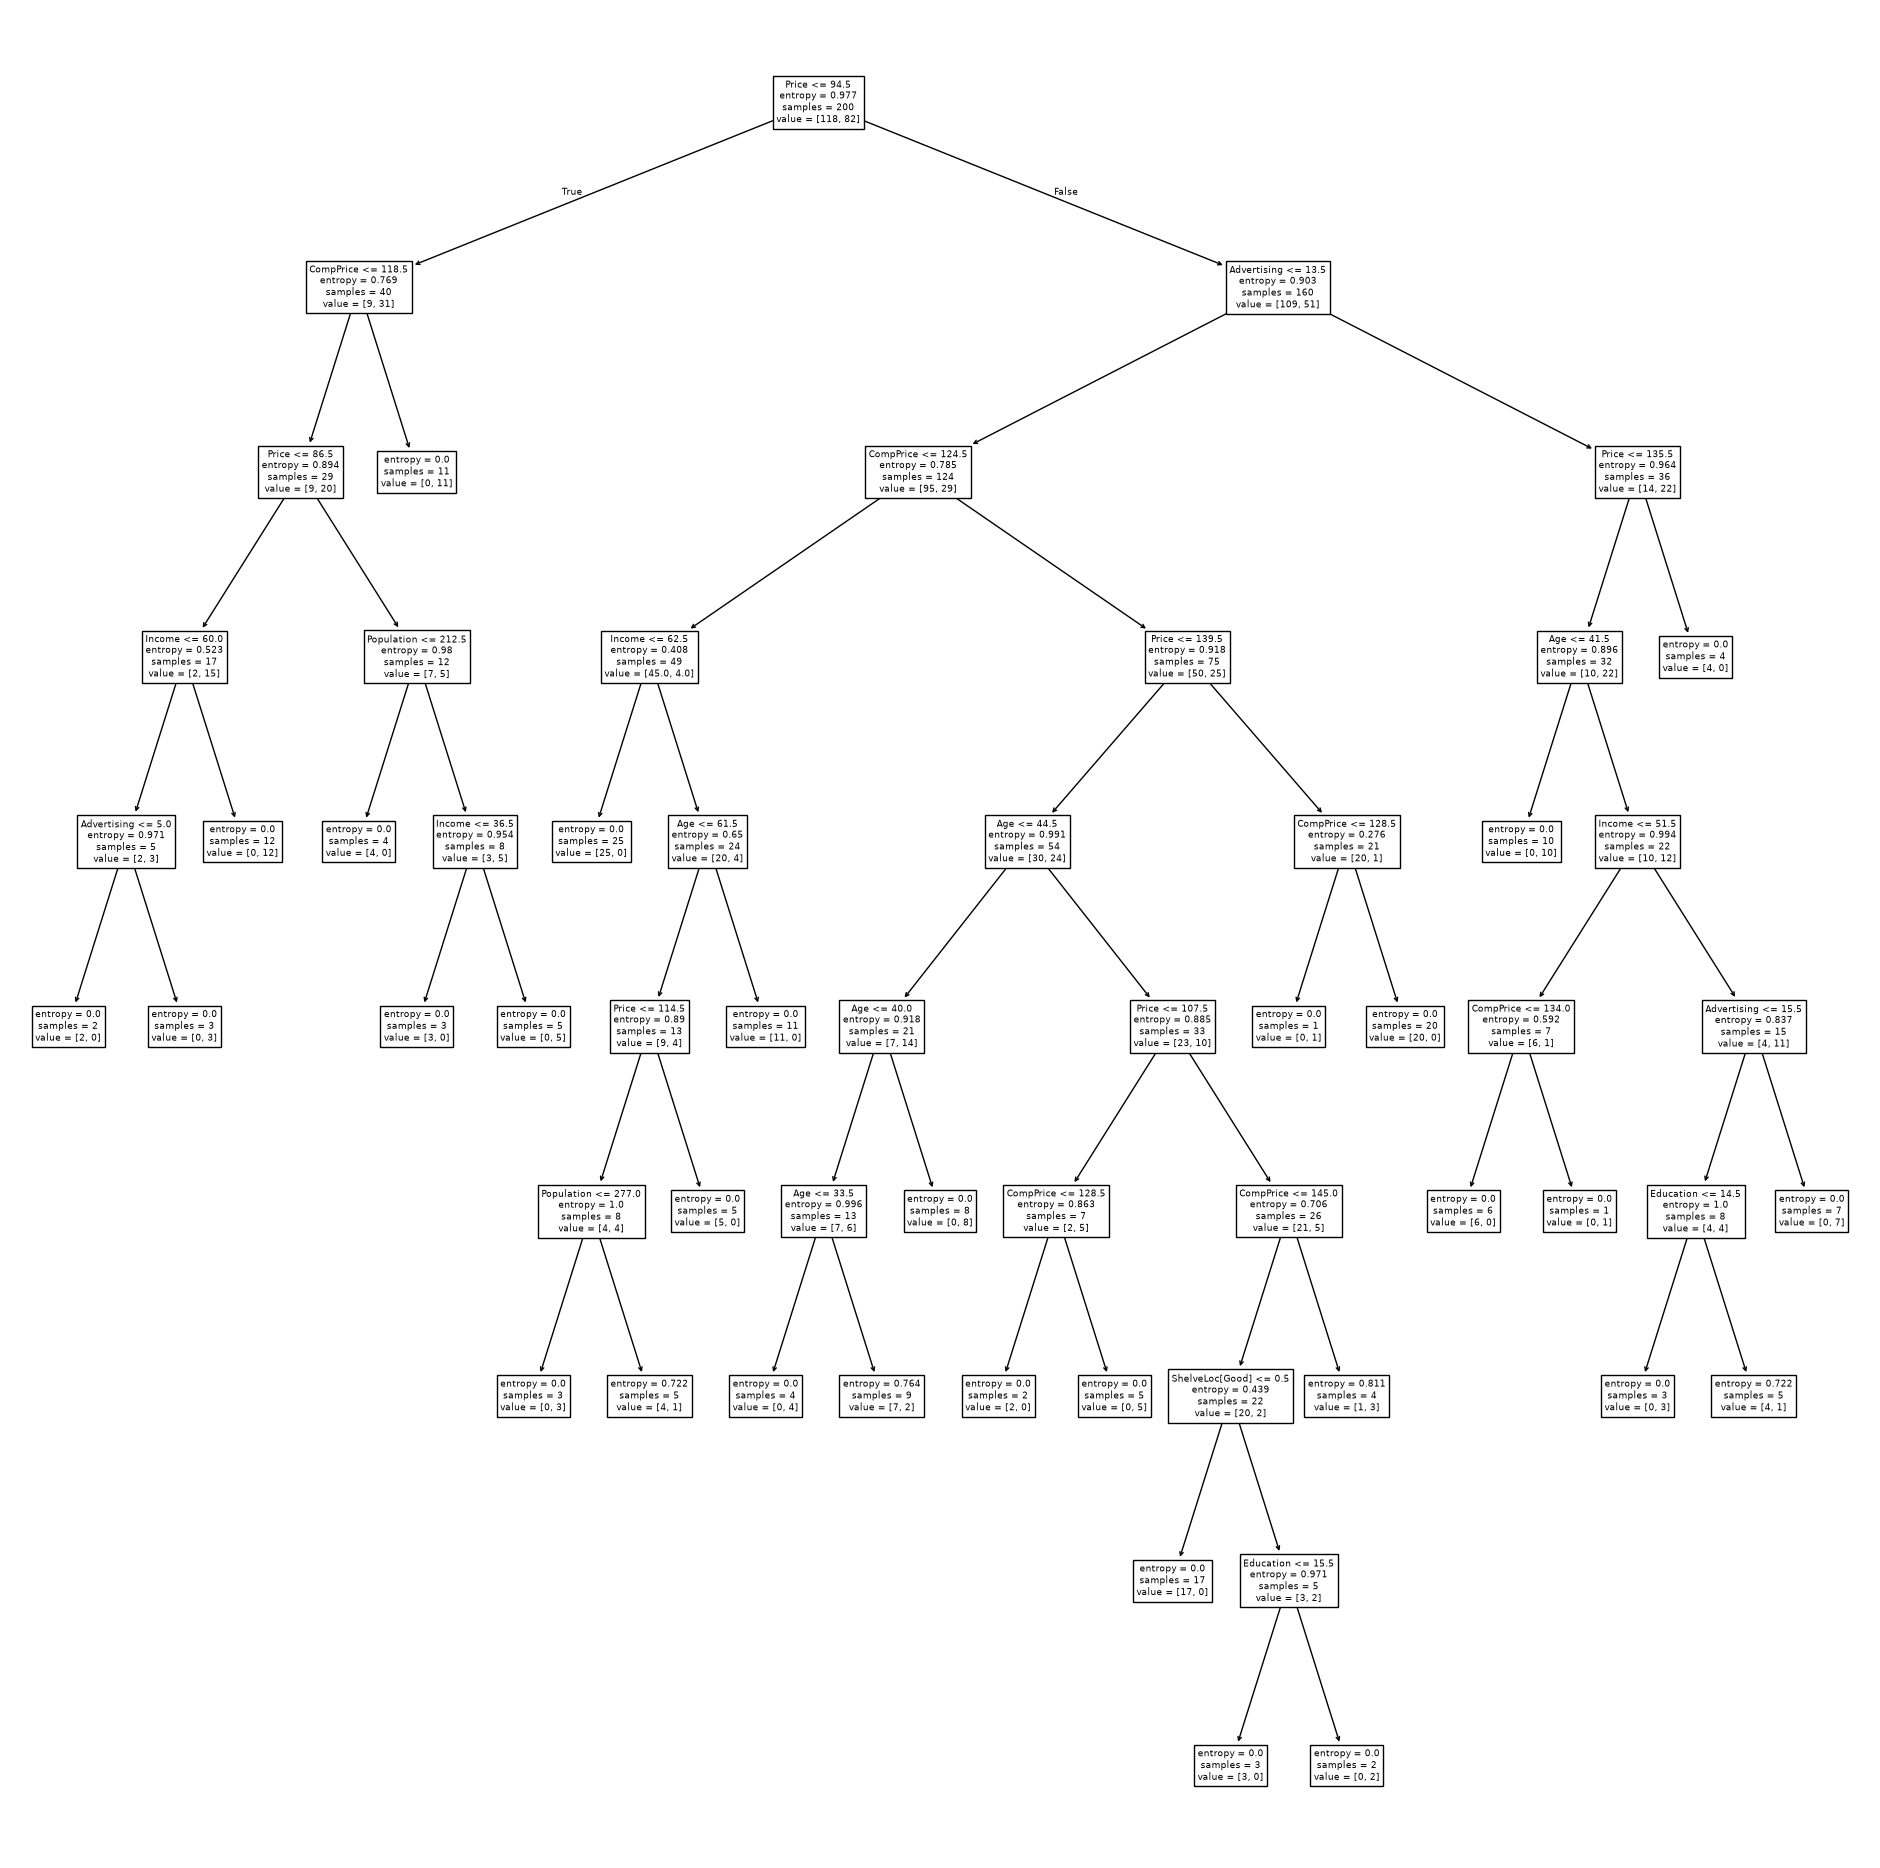

In [15]:
ax = subplots(figsize=(24, 24))[1]
best_ = grid.best_estimator_
plot_tree(best_,
          feature_names=feature_names,
          ax=ax);


This is quite a bushy tree. We could count the leaves, or query
`best_` instead.

In [16]:
best_.tree_.n_leaves


np.int64(30)

The tree with 30 terminal
nodes results in the lowest cross-validation error rate, with an accuracy of
68.5%. How well does this pruned tree perform on the test data set? Once
again, we apply the `predict()`  function.

In [17]:
print(accuracy_score(High_test,
                     best_.predict(X_test)))
confusion = confusion_table(best_.predict(X_test),
                            High_test)
confusion


0.72


Truth,No,Yes
Predicted,,
No,94,32
Yes,24,50


Now 72.0% of the test observations are correctly classified, which is slightly worse than the error for the full tree (with 35 leaves). So cross-validation has not helped us much here; it only pruned off 5 leaves, at a cost of a slightly worse error. These results would change if we were to change the random number seeds above; even though cross-validation gives an unbiased approach to model selection, it does have variance.

  

**Exercise 4** (Optional for report): Experiment with different random seeds in the cross-validation process used for cost-complexity pruning. Observe how the pruning results and test accuracy change with each seed. How consistent is the cross-validation pruning approach across different seeds?


      best_alpha  n_leaves  cv_accuracy  test_accuracy
seed                                                  
0         0.0180        30        0.725          0.720
1         0.0180        30        0.685          0.720
2         0.0227        21        0.715          0.690
3         0.0227        21        0.685          0.690
4         0.0450         3        0.675          0.690
5         0.0219        25        0.690          0.695
10        0.0321         5        0.655          0.690
21        0.0219        25        0.730          0.695
42        0.0242        19        0.685          0.675
123       0.0172        32        0.680          0.725

Summary across seeds:
       n_leaves  cv_accuracy  test_accuracy
count   10.0000      10.0000        10.0000
mean    21.1000       0.6925         0.6990
std      9.9939       0.0236         0.0166
min      3.0000       0.6550         0.6750
25%     19.5000       0.6812         0.6900
50%     23.0000       0.6850         0.6925
75%     2

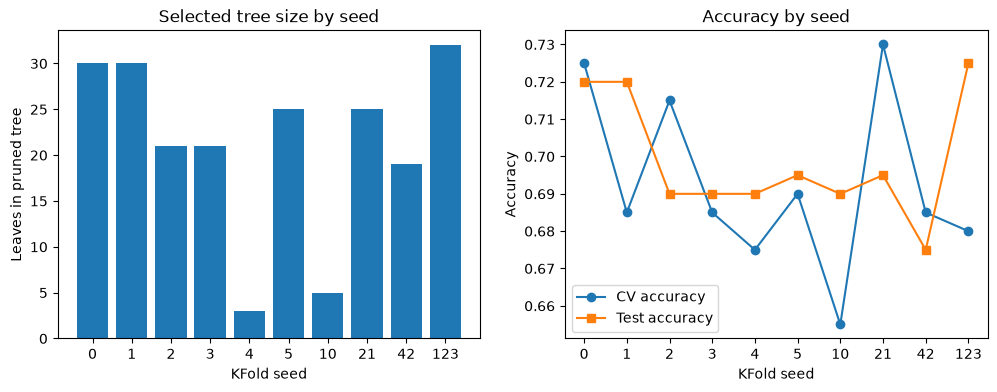

In [18]:
######### YOUR CODE HERE #########
# Repeat the CV pruning with different KFold seeds, keeping the
# train/test split and the candidate alphas fixed, so the only
# source of change is how the training data are cut into folds.
seeds = [0, 1, 2, 3, 4, 5, 10, 21, 42, 123]
rows = []
for s in seeds:
    kf = skm.KFold(10, random_state=s, shuffle=True)
    g = skm.GridSearchCV(DTC(criterion='entropy', random_state=0),
                         {'ccp_alpha': ccp_path.ccp_alphas},
                         refit=True,
                         cv=kf,
                         scoring='accuracy')
    g.fit(X_train, High_train)
    b = g.best_estimator_
    rows.append({'seed': s,
                 'best_alpha': g.best_params_['ccp_alpha'],
                 'n_leaves': b.tree_.n_leaves,
                 'cv_accuracy': g.best_score_,
                 'test_accuracy': accuracy_score(High_test, b.predict(X_test))})

seed_results = pd.DataFrame(rows).set_index('seed')
print(seed_results.round(4))
print('\nSummary across seeds:')
print(seed_results[['n_leaves', 'cv_accuracy', 'test_accuracy']].describe().round(4))

# Visualise: chosen tree size vs. test accuracy for each seed
fig, axes = subplots(1, 2, figsize=(12, 4))
axes[0].bar(seed_results.index.astype(str), seed_results['n_leaves'])
axes[0].set_xlabel('KFold seed'); axes[0].set_ylabel('Leaves in pruned tree')
axes[0].set_title('Selected tree size by seed')
axes[1].plot(seed_results.index.astype(str), seed_results['cv_accuracy'], 'o-', label='CV accuracy')
axes[1].plot(seed_results.index.astype(str), seed_results['test_accuracy'], 's-', label='Test accuracy')
axes[1].set_xlabel('KFold seed'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy by seed'); axes[1].legend();
###### YOUR CODE ENDS HERE #######

## Fitting Regression Trees
Here we fit a regression tree to the  `Boston`  data set. The
steps are similar to those for classification trees.

In [19]:
Boston = load_data("Boston")
model = MS(Boston.columns.drop('medv'), intercept=False)
D = model.fit_transform(Boston)
feature_names = list(D.columns)
X = np.asarray(D)


c:\Users\Vicente\Desktop\Lund - MSc Economics\ML - From a Regression perspective\ml-course\.venv\Lib\site-packages\sklearn\base.py:969: FutureWarning: ModelSpec will move to its own package in ISLP 0.7. `from ISLP.models import ModelSpec` (and the other tools of ISLP.models that build model matrices) will keep working, but other import paths, such as ISLP.models.model_spec, may not, and `intercept` will then default to False. To silence this warning: warnings.filterwarnings('ignore', message='ModelSpec will move').
  return self.fit(X, **fit_params).transform(X)


First, we split the data into training and test sets, and fit the tree
to the training data. Here we use 30% of the data for the test set.


In [20]:
(X_train,
 X_test,
 y_train,
 y_test) = skm.train_test_split(X,
                                Boston['medv'],
                                test_size=0.3,
                                random_state=0)


Having formed  our training  and test data sets, we fit the regression tree.

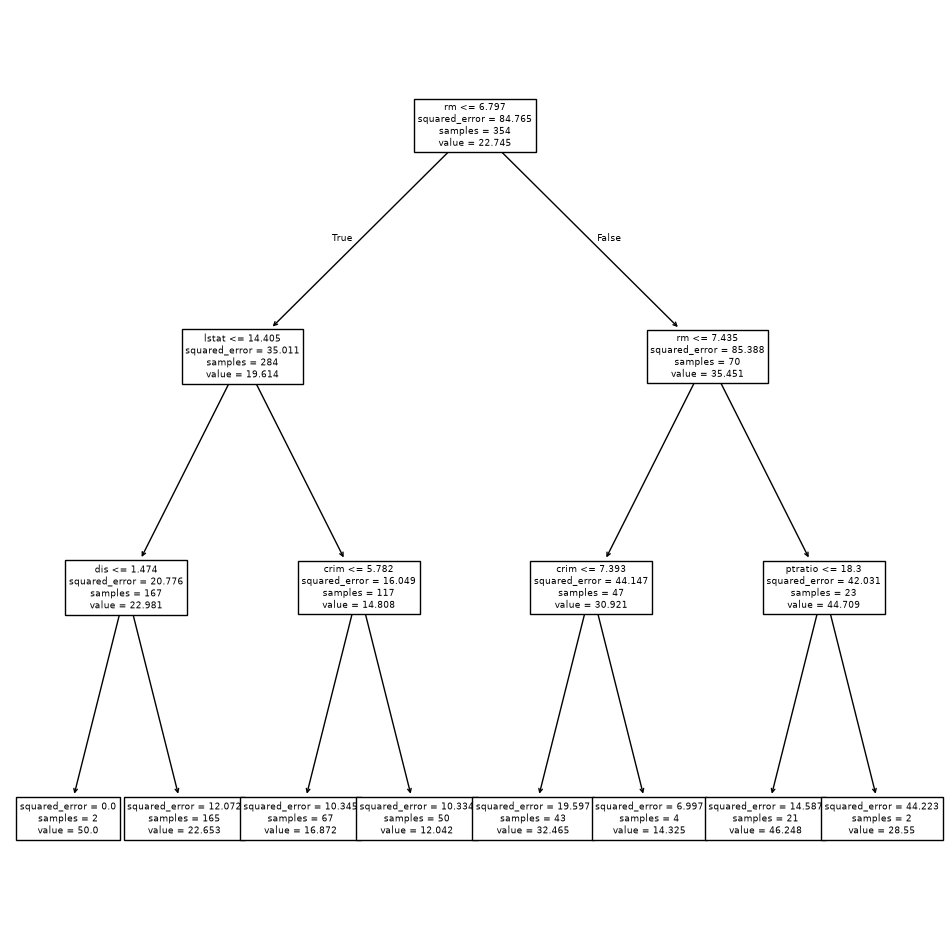

In [21]:
reg = DTR(max_depth=3, random_state=0)
reg.fit(X_train, y_train)
ax = subplots(figsize=(12,12))[1]
plot_tree(reg,
          feature_names=feature_names,
          ax=ax);


The variable `lstat` measures the percentage of individuals with
lower socioeconomic status. The tree indicates that lower
values of `lstat` correspond to more expensive houses.
The tree predicts a median house price of $12,042 for small-sized homes (`rm < 6.8`), in
suburbs in which residents have low socioeconomic status (`lstat  > 14.4`) and the crime-rate is moderate (`crim > 5.8`).

Now we use the cross-validation function to see whether pruning
the tree will improve performance.

In [22]:
ccp_path = reg.cost_complexity_pruning_path(X_train, y_train)
kfold = skm.KFold(5,
                  shuffle=True,
                  random_state=10)
grid = skm.GridSearchCV(reg,
                        {'ccp_alpha': ccp_path.ccp_alphas},
                        refit=True,
                        cv=kfold,
                        scoring='neg_mean_squared_error')
G = grid.fit(X_train, y_train)


In keeping with the cross-validation results, we use the pruned tree
to make predictions on the test set.

In [23]:
best_ = grid.best_estimator_
np.mean((y_test - best_.predict(X_test))**2)


np.float64(28.06985754975404)

In other words, the test set MSE associated with the regression tree
is 28.07.  The square root of
the MSE is therefore around
5.30,
indicating that this model leads to test predictions that are within around
$5300
of the true median home value for the suburb.

Let’s plot the best tree to see how interpretable it is.

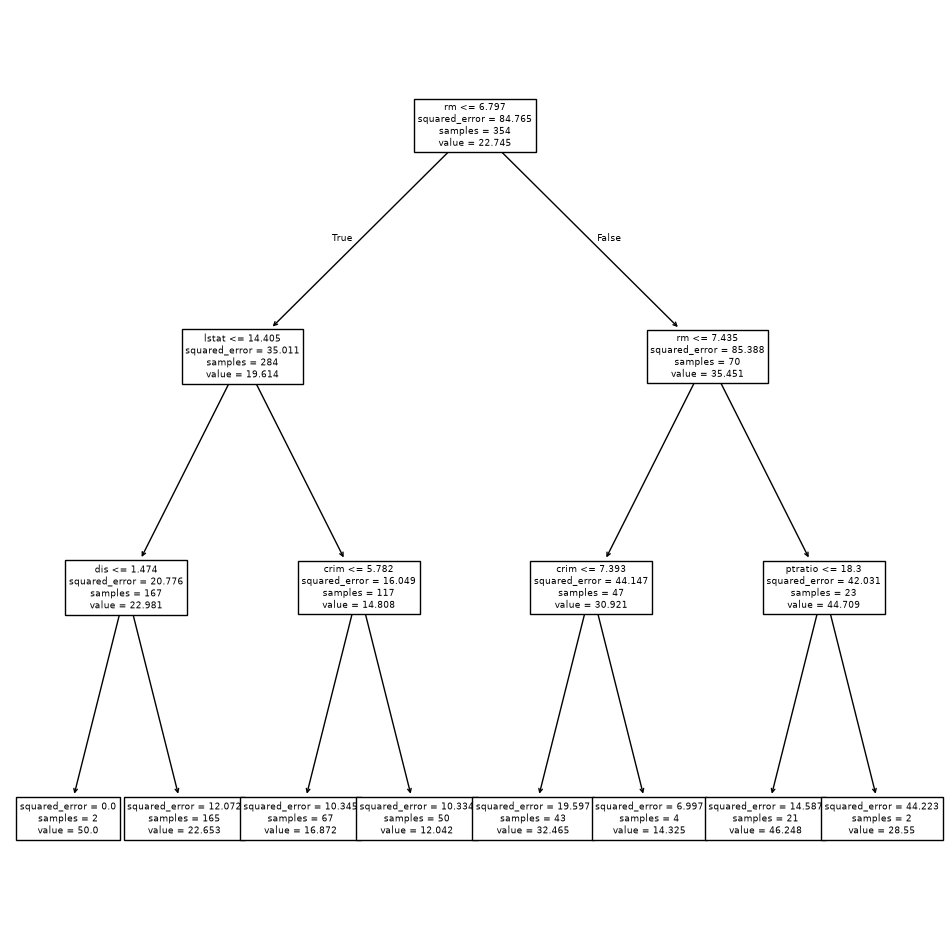

In [24]:
ax = subplots(figsize=(12,12))[1]
plot_tree(G.best_estimator_,
          feature_names=feature_names,
          ax=ax);


**Exercise 5 (Optional for report)**: Modify the target variable by using the log-transformed median house value (`log_medv = log(medv)`). Re-fit the regression tree model with the same parameters and perform cost-complexity pruning. 

After fitting, back-transform the predictions and compare the test MSE on the original scale. What differences do you observe in model performance and tree structure?


                                   model  test MSE  leaves
0                           tree on medv    28.070       8
1  tree on log(medv), exp back-transform    24.838       8
2  tree on log(medv), smearing-corrected    24.460       8
Smearing factor: 1.0156
|--- lstat <= 14.40
|   |--- rm <= 6.68
|   |   |--- lstat <= 9.71
|   |   |   |--- value: [3.18]
|   |   |--- lstat >  9.71
|   |   |   |--- value: [3.02]
|   |--- rm >  6.68
|   |   |--- rm <= 7.43
|   |   |   |--- value: [3.43]
|   |   |--- rm >  7.43
|   |   |   |--- value: [3.79]
|--- lstat >  14.40
|   |--- crim <= 5.78
|   |   |--- tax <= 688.50
|   |   |   |--- value: [2.84]
|   |   |--- tax >  688.50
|   |   |   |--- value: [2.25]
|   |--- crim >  5.78
|   |   |--- crim <= 38.01
|   |   |   |--- value: [2.51]
|   |   |--- crim >  38.01
|   |   |   |--- value: [1.93]



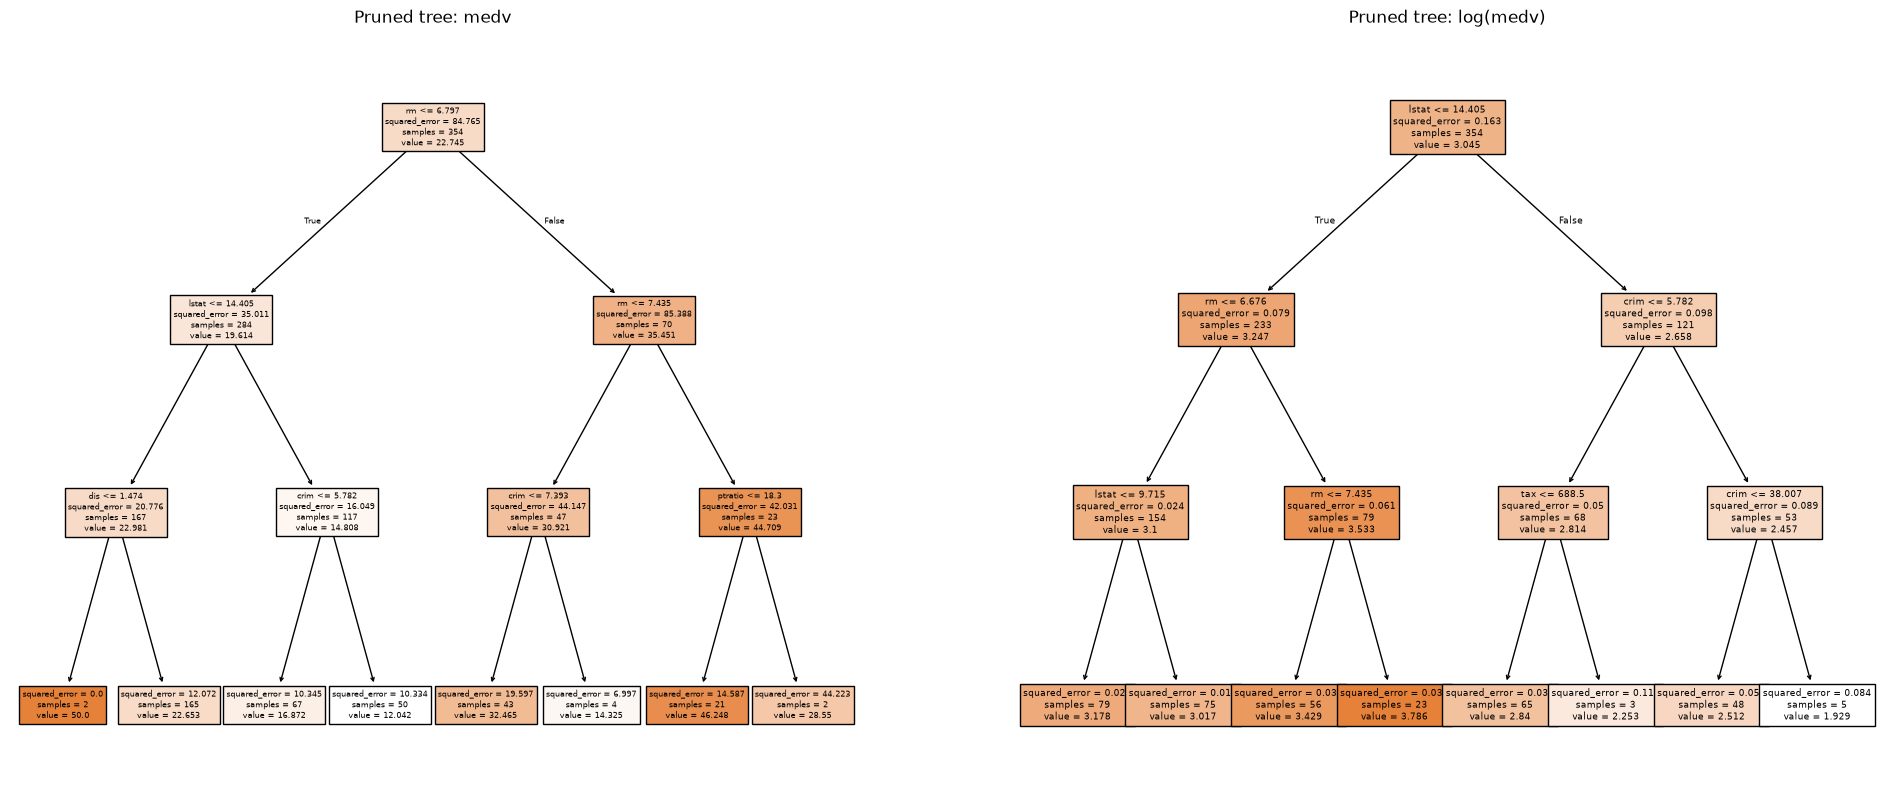

In [25]:
######### YOUR CODE HERE #########
# 1) Log-transform the target
log_y_train = np.log(y_train)

# 2) Same model and pruning procedure as for medv (max_depth=3, same kfold)
reg_log = DTR(max_depth=3, random_state=0)
reg_log.fit(X_train, log_y_train)
ccp_path_log = reg_log.cost_complexity_pruning_path(X_train, log_y_train)
grid_log = skm.GridSearchCV(reg_log,
                            {'ccp_alpha': ccp_path_log.ccp_alphas},
                            refit=True,
                            cv=kfold,
                            scoring='neg_mean_squared_error')
G_log = grid_log.fit(X_train, log_y_train)
best_log = G_log.best_estimator_

# 3) Back-transform predictions to the original scale.
#    Naive: exp(prediction) estimates the *median* (geometric mean), not the mean,
#    so we also show Duan's smearing correction: multiply by mean(exp(residuals)).
log_pred_test = best_log.predict(X_test)
pred_naive = np.exp(log_pred_test)
smear = np.mean(np.exp(log_y_train - best_log.predict(X_train)))
pred_smear = pred_naive * smear

mse_orig  = np.mean((y_test - best_.predict(X_test))**2)   # pruned tree on medv (from above)
mse_naive = np.mean((y_test - pred_naive)**2)
mse_smear = np.mean((y_test - pred_smear)**2)

print(pd.DataFrame({
    'model': ['tree on medv', 'tree on log(medv), exp back-transform',
              'tree on log(medv), smearing-corrected'],
    'test MSE': [mse_orig, mse_naive, mse_smear],
    'leaves': [best_.tree_.n_leaves, best_log.tree_.n_leaves, best_log.tree_.n_leaves]
}).round(3))
print(f'Smearing factor: {smear:.4f}')

# 4) Compare tree structures side by side
fig, axes = subplots(1, 2, figsize=(24, 10))
plot_tree(best_, feature_names=feature_names, ax=axes[0], filled=True)
axes[0].set_title('Pruned tree: medv')
plot_tree(best_log, feature_names=feature_names, ax=axes[1], filled=True)
axes[1].set_title('Pruned tree: log(medv)');

print(export_text(best_log, feature_names=feature_names))
###### YOUR CODE ENDS HERE #######

## Bagging and Random Forests

Here we apply bagging and random forests to the `Boston` data, using
the `RandomForestRegressor()` from the `sklearn.ensemble` package. Recall
that bagging is simply a special case of a random forest with
$m=p$. Therefore, the `RandomForestRegressor()`  function can be used to
perform both bagging and random forests. We start with bagging.

In [26]:
bag_boston = RF(max_features=X_train.shape[1], random_state=0)
bag_boston.fit(X_train, y_train)


,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",12
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

The argument `max_features` indicates that all 12 predictors should
be considered for each split of the tree --- in other words, that
bagging should be done.  How well does this bagged model perform on
the test set?

np.float64(14.612930407894737)

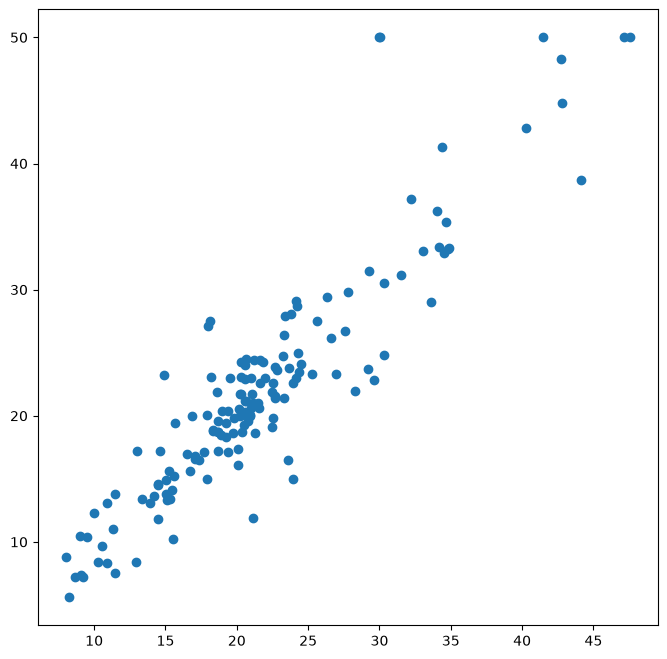

In [27]:
ax = subplots(figsize=(8,8))[1]
y_hat_bag = bag_boston.predict(X_test)
ax.scatter(y_hat_bag, y_test)
np.mean((y_test - y_hat_bag)**2)


The test set MSE associated with the bagged regression tree is
14.63, about half that obtained using an optimally-pruned single
tree.  We could change the number of trees grown from the default of
100 by
using the `n_estimators` argument:

In [28]:
bag_boston = RF(max_features=X_train.shape[1],
                n_estimators=500,
                random_state=0).fit(X_train, y_train)
y_hat_bag = bag_boston.predict(X_test)
np.mean((y_test - y_hat_bag)**2)

np.float64(14.610410025789477)

There is not much change. Bagging and random forests cannot overfit by
increasing the number of trees, but can underfit if the number is too small.

Growing a random forest proceeds in exactly the same way, except that
we use a smaller value of the `max_features` argument. By default,
`RandomForestRegressor()`  uses $p$ variables when building a random
forest of regression trees (i.e. it defaults to bagging), and `RandomForestClassifier()` uses
$\sqrt{p}$ variables when building a
random forest of classification trees. Here we use `max_features=6`.

In [29]:
RF_boston = RF(max_features=6,
               random_state=0).fit(X_train, y_train)
y_hat_RF = RF_boston.predict(X_test)
np.mean((y_test - y_hat_RF)**2)


np.float64(20.261844203947373)

The test set MSE is about 20;
this indicates that random forests did somewhat worse than bagging
in this case. Extracting the `feature_importances_` values from the fitted model, we can view the
importance of each variable.

In [30]:
feature_imp = pd.DataFrame(
    {'importance':RF_boston.feature_importances_},
    index=feature_names)
feature_imp.sort_values(by='importance', ascending=False)

,importance
lstat,0.357250
rm,0.332050
ptratio,0.068107
crim,0.058243
indus,0.052632
dis,0.042471
nox,0.032385
tax,0.025497
age,0.020530
rad,0.005148


 This
is a relative measure of the total decrease in node impurity that results from
splits over that variable, averaged over all trees (this was plotted in Figure 8.9 for a model fit to the `Heart` data). 

The results indicate that across all of the trees considered in the
random forest, the wealth level of the community (`lstat`) and the
house size (`rm`) are by far the two most important variables.

  

**Exercise 6 (Optional for report)**: Evaluate importance of variables of the fitted model using permutation importance. Plot the permutation importances and compare them with the previously calculated impurity-based feature importances. Refer to the [Permutation Importance documentation](https://scikit-learn.org/stable/modules/permutation_importance.html) for more details.


         importance  perm_importance_mean  perm_importance_std  impurity_norm  \
lstat        0.3572               36.1788               6.0230         0.3572   
rm           0.3321               23.7057               2.8480         0.3321   
nox          0.0324                2.4292               0.5446         0.0324   
dis          0.0425                1.6954               0.3959         0.0425   
ptratio      0.0681                1.6564               0.6547         0.0681   
tax          0.0255                0.7122               0.2629         0.0255   
age          0.0205                0.4512               0.2564         0.0205   
crim         0.0582                0.3575               0.7374         0.0582   
indus        0.0526                0.2954               0.2497         0.0526   
rad          0.0051                0.2033               0.0956         0.0051   
chas         0.0034                0.0816               0.1410         0.0034   
zn           0.0023         

TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

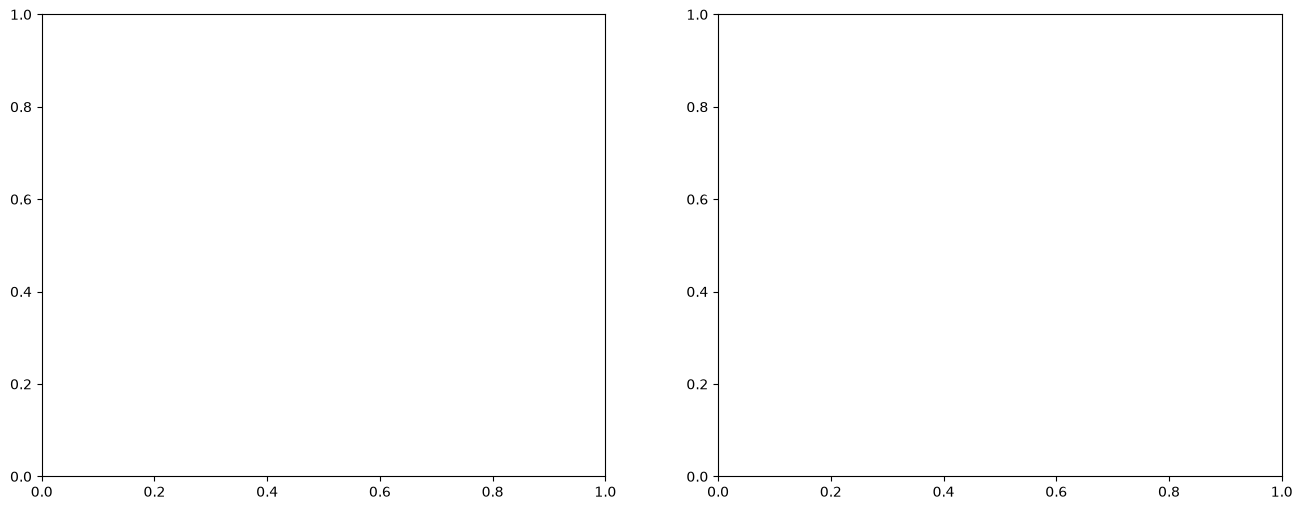

In [31]:
######### YOUR CODE HERE #########
from sklearn.inspection import permutation_importance

# Permutation importance on the TEST set: how much does the MSE increase
# when we randomly shuffle one feature (breaking its link with y)?
perm = permutation_importance(RF_boston,
                              X_test,
                              y_test,
                              n_repeats=30,
                              random_state=0,
                              scoring='neg_mean_squared_error')

perm_imp = pd.DataFrame({'perm_importance_mean': perm.importances_mean,
                         'perm_importance_std': perm.importances_std},
                        index=feature_names)

comparison = feature_imp.join(perm_imp)
# Normalise both to sum to 1 so they can be compared on the same scale
comparison['impurity_norm'] = comparison['importance'] / comparison['importance'].sum()
comparison['perm_norm'] = (comparison['perm_importance_mean'].clip(lower=0)
                           / comparison['perm_importance_mean'].clip(lower=0).sum())
comparison = comparison.sort_values('perm_importance_mean', ascending=False)
print(comparison.round(4))

# Plot 1: distribution of permutation importances (increase in test MSE)
order = comparison.index
fig, axes = subplots(1, 2, figsize=(16, 6))
idx = [feature_names.index(f) for f in order][::-1]
axes[0].boxplot(perm.importances[idx].T, vert=False,
                labels=[feature_names[i] for i in idx])
axes[0].axvline(0, color='k', ls='--', lw=0.8)
axes[0].set_xlabel('Increase in test MSE when feature is permuted')
axes[0].set_title('Permutation importance (test set, 30 repeats)')

# Plot 2: side-by-side normalised comparison
y_pos = np.arange(len(order))
axes[1].barh(y_pos - 0.2, comparison['impurity_norm'][::-1], height=0.4,
             label='Impurity-based (MDI)')
axes[1].barh(y_pos + 0.2, comparison['perm_norm'][::-1], height=0.4,
             label='Permutation')
axes[1].set_yticks(y_pos); axes[1].set_yticklabels(order[::-1])
axes[1].set_xlabel('Normalised importance')
axes[1].set_title('Impurity vs permutation importance'); axes[1].legend();
######### YOUR CODE ENDS HERE #######

## Boosting

Here we use `GradientBoostingRegressor()` from `sklearn.ensemble`
to fit boosted regression trees to the `Boston` data
set. For classification we would  use `GradientBoostingClassifier()`.
The argument `n_estimators=5000`
indicates that we want 5000 trees, and the option
`max_depth=3` limits the depth of each tree. The
argument `learning_rate` is the $\lambda$
mentioned earlier in the description of boosting.

In [32]:
boost_boston = GBR(n_estimators=5000,
                   learning_rate=0.001,
                   max_depth=3,
                   random_state=0)
boost_boston.fit(X_train, y_train)


,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.001
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",5000
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, i

We can see how the training error decreases with the `train_score_` attribute.
To get an idea of how the test error decreases we can use the
`staged_predict()` method to get the predicted values along the path.

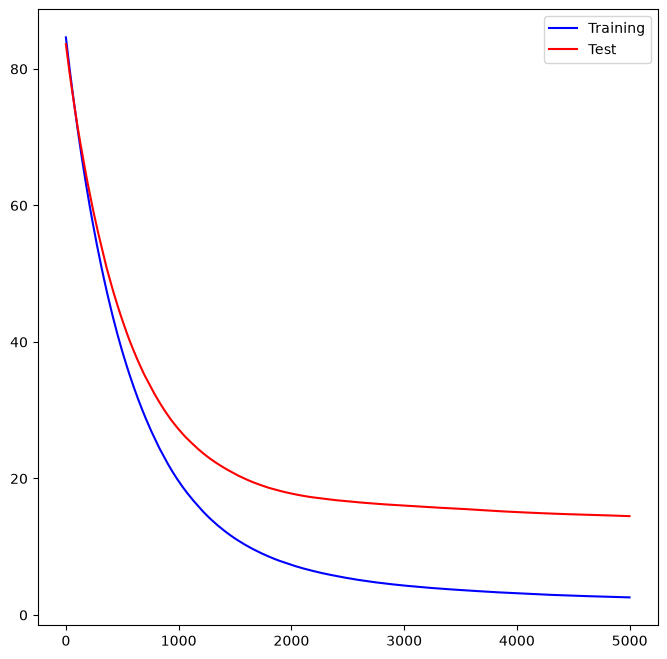

In [33]:
test_error = np.zeros_like(boost_boston.train_score_)
for idx, y_ in enumerate(boost_boston.staged_predict(X_test)):
   test_error[idx] = np.mean((y_test - y_)**2)

plot_idx = np.arange(boost_boston.train_score_.shape[0])
ax = subplots(figsize=(8,8))[1]
ax.plot(plot_idx,
        boost_boston.train_score_,
        'b',
        label='Training')
ax.plot(plot_idx,
        test_error,
        'r',
        label='Test')
ax.legend();


We now use the boosted model to predict `medv` on the test set:

In [34]:
y_hat_boost = boost_boston.predict(X_test);
np.mean((y_test - y_hat_boost)**2)


np.float64(14.484189040407578)

 The test MSE obtained is 14.48,
similar to the test MSE for bagging. If we want to, we can
perform boosting with a different value of the shrinkage parameter
$\lambda$ in (8.10). The default value is 0.001, but
this is easily modified.  Here we take $\lambda=0.2$.

In [35]:
boost_boston = GBR(n_estimators=5000,
                   learning_rate=0.2,
                   max_depth=3,
                   random_state=0)
boost_boston.fit(X_train,
                 y_train)
y_hat_boost = boost_boston.predict(X_test);
np.mean((y_test - y_hat_boost)**2)


np.float64(14.501514553719547)

In this case, using $\lambda=0.2$ leads to almost the same test MSE
as when using $\lambda=0.001$.

 

### XGBoost

XGBoost, which stands for **eXtreme Gradient Boosting**, is an optimized version of the traditional gradient boosting algorithm. It includes several enhancements such as:
- Regularization
- Efficient Computation
- Handling Missing Values
- Advanced Tree Pruning

XGBoost is often more efficient and robust than standard gradient boosting methods, especially on large and complex datasets. Read [XGBoost tutorials](https://xgboost.readthedocs.io/en/stable/tutorials/model.html) for details.


**Exercise 7 (Optional for report)**: Implement an XGBoost model using the `xgboost` package with the same parameters as the existing gradient boosting model (`n_estimators=5000`, `max_depth=3`, and `learning_rate=0.2`), and add L2 regularization (`reg_lambda=0.01`).

Evaluate the model using staged predictions to track the training and test MSE as the number of trees increases. Compare the results with the existing gradient boosting model `boost_boston` and discuss any differences in performance. Refer to the [XGBoost documentation](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBRegressor) for details.


In [36]:
######### YOUR CODE HERE #########

###### YOUR CODE ENDS HERE #######

## Bayesian Additive Regression Trees (Optional for report)

In this section we demonstrate a  `Python` implementation of BART found in the
`ISLP.bart` package. We fit a  model
to the `Boston` housing data set. This `BART()` estimator is
designed for quantitative outcome variables, though other implementations are available for
fitting logistic and probit models to categorical outcomes.

In [37]:
bart_boston = BART(random_state=0, burnin=5, ndraw=15)
bart_boston.fit(X_train, y_train)


,ndraw,15
,burnin,5
,random_state,0
,num_trees,200
,num_particles,10
,max_stages,5000
,split_prob,<function BAR...001DF7D3B8040>
,min_depth,0
,std_scale,2
,split_prior,None
,sigma_prior,"(5, ...)"


On this data set, with this split into test and training, we see that the test error of BART is similar to that of  random forest.

In [38]:
yhat_test = bart_boston.predict(X_test.astype(np.float32))
np.mean((y_test - yhat_test)**2)


np.float64(22.145009458109232)

We can check how many times each variable appeared in the collection of trees.
This gives a summary similar to the variable importance plot for boosting and random forests.

In [39]:
var_inclusion = pd.Series(bart_boston.variable_inclusion_.mean(0),
                               index=D.columns)
var_inclusion


crim       26.933333
zn         27.866667
indus      26.466667
chas       22.466667
nox        26.600000
rm         29.800000
age        22.733333
dis        26.466667
rad        23.666667
tax        24.133333
ptratio    24.266667
lstat      31.000000
dtype: float64